# Stages 3 & 4 — Preprocessing / QC and Exploratory Data Analysis
**Author:** Ian Tuitoek  |  **Project:** SARS-CoV-2 genomes (Nextstrain), Bioinformatics group project

The research question, objectives and hypothesis are stated in Stage 1 of the main project notebook. This notebook picks up from Stage 2 (data acquisition) and covers:

| Task | Stage | What this notebook produces |
|---|---|---|
| 4 | 3. Preprocessing and quality control | Filter incomplete sequences, extract genes, **before/after counts**, comments on anything suspicious |
| 5 | 4. Exploratory data analysis | **Five informative plots** with interpretation |

**Outputs written by this notebook**
- `data/processed/clean_sequences.fasta`: sequences that passed QC
- `data/processed/gene_<GENE>.fasta`: one FASTA per extracted gene
- `data/processed/clean_metadata.csv`: metadata for the sequences that passed QC
- `results/qc_funnel.csv`, `results/gene_extraction_summary.csv`: before/after counts
- `results/figures/fig1…fig5*.png`: the EDA figures

In [1]:
%pip install -q biopython mappy pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os, subprocess

# Detect Google Colab (same approach as the main notebook)
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    colab_root = Path("/content/bioinformatics-group-project")
    if not colab_root.exists():
        subprocess.run(["git", "clone",
                        "https://github.com/JudahNdivo/bioinformatics-group-project.git",
                        str(colab_root)], check=True)
    os.chdir(colab_root)

# Find the project root whether the notebook runs from the repo root or from notebooks/
cwd = Path.cwd()
if (cwd / "data").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not find the project's data/ folder. Open the repository folder in VS Code.")

DATA_DIR = PROJECT_ROOT / "data"
OUT_DIR = DATA_DIR / "processed"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Environment :", "Google Colab" if IN_COLAB else "Local (VS Code)")
print("Project root:", PROJECT_ROOT)
print("Data files  :", sorted(p.name for p in DATA_DIR.iterdir() if p.is_file()))

Environment : Local (VS Code)
Project root: /Users/ian/4.2 Projects/bioinformatics-group-project
Data files  : ['metadata.tsv.xz', 'metadata_template.csv', 'sequences.fasta.xz', 'wuhan_reference.fasta']


---
# Stage 3 — Preprocessing and quality control (Task 4)

**Plan**
1. Load the metadata and the reference genome (NC_045512.2).
2. Remove duplicate IDs and sequences with no metadata.
3. Filter incomplete or low-quality sequences (too short, too many `N`/ambiguous bases).
4. Align each remaining genome to the reference and **extract each gene** using the reference coordinates.
5. Check the results against biology we know must hold, and record **before/after counts** at every step.

The thresholds below are choices the group can change; every count in the report updates automatically.

In [3]:
import lzma
import numpy as np
import pandas as pd
import mappy as mp
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord

#  QC thresholds (change here, re-run the notebook)
MIN_LEN        = 29_000   # keep genomes >= 29,000 nt (~97% of the 29,903 nt reference)
MAX_AMBIG_FRAC = 0.01     # keep genomes with <= 1% N / ambiguous bases
MIN_GENOME_COV = 0.90     # share of reference positions that must align to the query
MIN_GENE_COV   = 0.95     # a gene counts as 'complete' if >= 95% of it aligns ...
MAX_GENE_AMBIG = 0.01     # ... and it has <= 1% N / ambiguous bases
MAX_SEQS       = None     # set e.g. 500 for a quick test run; None = use everything
N_PCA          = 3000     # max number of genomes used for the PCA in Stage 4

# SARS-CoV-2 (NC_045512.2) gene coordinates, 1-based inclusive
GENES = {"ORF1ab": (266, 21555), "S": (21563, 25384), "ORF3a": (25393, 26220), "E": (26245, 26472),
         "M": (26523, 27191), "ORF6": (27202, 27387), "ORF7a": (27394, 27759), "ORF8": (27894, 28259),
         "N": (28274, 29533), "ORF10": (29558, 29674)}
GENES0 = {g: (a - 1, b) for g, (a, b) in GENES.items()}      # 0-based, end-exclusive

# Load reference + metadata 
reference = SeqIO.read(DATA_DIR / "wuhan_reference.fasta", "fasta")
ref_seq = str(reference.seq).upper()
REF_LEN = len(ref_seq)
assert reference.id == "NC_045512.2" and REF_LEN == 29903, "Unexpected reference genome"

meta_raw = pd.read_csv(DATA_DIR / "metadata.tsv.xz", sep="\t", compression="xz", low_memory=False)
needed = ["strain", "clade_who", "date", "country", "host"]
missing = [c for c in needed if c not in meta_raw.columns]
if missing:
    raise KeyError(f"Metadata is missing expected columns: {missing}")
meta = meta_raw.drop_duplicates("strain").copy()
meta["strain"] = meta["strain"].astype(str)

print(f"Metadata rows: {len(meta_raw):,} (unique strains: {len(meta):,})")
print(f"Reference: {reference.id}, {REF_LEN:,} nt")

Metadata rows: 5,097 (unique strains: 5,097)
Reference: NC_045512.2, 29,903 nt


### 3.1 Sanity-check the gene coordinates against biology
Before trusting the coordinates, confirm on the reference that each gene looks like a real coding sequence: starts with `ATG`, ends with a stop codon, is a multiple of 3, and has no stop codon inside. **ORF1ab is the known exception**: it is translated through a ribosomal frameshift, so its length is not a multiple of 3 and it is excluded from the in-frame test.

In [4]:
checks = []
for g, (a, b) in GENES0.items():
    nt = ref_seq[a:b]
    in_frame = len(nt) % 3 == 0
    checks.append({
        "gene": g, "length_nt": len(nt), "multiple_of_3": in_frame,
        "starts_ATG": nt.startswith("ATG"),
        "ends_with_stop": nt[-3:] in ("TAA", "TAG", "TGA"),
        "internal_stop_codons": str(Seq(nt).translate())[:-1].count("*") if in_frame else None,
    })
ref_check = pd.DataFrame(checks).set_index("gene")
display(ref_check)

bad = ref_check.drop(index="ORF1ab")
assert bad.multiple_of_3.all() and bad.starts_ATG.all() and bad.ends_with_stop.all() \
    and (bad.internal_stop_codons == 0).all(), "Gene coordinates do not look like real ORFs; check them"
print("All genes except ORF1ab are clean ORFs, so the coordinates are consistent with the reference.")

,length_nt,multiple_of_3,starts_ATG,ends_with_stop,internal_stop_codons
gene,,,,,
ORF1ab,21290,False,True,True,NaN
S,3822,True,True,True,0.0
ORF3a,828,True,True,True,0.0
E,228,True,True,True,0.0
M,669,True,True,True,0.0
ORF6,186,True,True,True,0.0
ORF7a,366,True,True,True,0.0
ORF8,366,True,True,True,0.0
N,1260,True,True,True,0.0


All genes except ORF1ab are clean ORFs, so the coordinates are consistent with the reference.


### 3.2 Read the FASTA and apply the basic filters
For every record we measure its length and the fraction of non-`ACGT` characters (N and IUPAC ambiguity codes). Only sequences that pass go forward, so memory stays small.

In [5]:
valid_ids = set(meta["strain"])
seen, stats, seqs = set(), [], {}
raw_records = 0

with lzma.open(DATA_DIR / "sequences.fasta.xz", "rt") as handle:
    for rec in SeqIO.parse(handle, "fasta"):
        if MAX_SEQS and raw_records >= MAX_SEQS:
            break
        raw_records += 1
        if rec.id in seen:                       # duplicate ID: keep the first occurrence only
            stats.append({"strain": rec.id, "duplicate_id": True})
            continue
        seen.add(rec.id)
        s = str(rec.seq).upper().replace("-", "")
        acgt = sum(s.count(b) for b in "ACGT")
        row = {"strain": rec.id, "duplicate_id": False, "length": len(s),
               "ambig_frac": (1 - acgt / len(s)) if s else 1.0, "in_metadata": rec.id in valid_ids}
        stats.append(row)
        if row["in_metadata"] and row["length"] >= MIN_LEN and row["ambig_frac"] <= MAX_AMBIG_FRAC:
            seqs[rec.id] = s

st = pd.DataFrame(stats)
uniq = st[~st["duplicate_id"]].copy()
uniq["length"] = uniq["length"].astype(int)            # (duplicate rows have no length -> float/NaN)
uniq["in_metadata"] = uniq["in_metadata"].astype(bool)
step_meta = uniq[uniq["in_metadata"]]
step_len = step_meta[step_meta["length"] >= MIN_LEN]
step_amb = step_len[step_len["ambig_frac"] <= MAX_AMBIG_FRAC]
print(f"Read {raw_records:,} FASTA records; {len(seqs):,} pass the length / ambiguity / metadata filters.")

Read 5,097 FASTA records; 2,811 pass the length / ambiguity / metadata filters.


### 3.3 Align to the reference and extract the genes
Each genome is aligned to NC_045512.2 with minimap2 (via `mappy`). The alignment gives, for every reference position, the matching position in the query, so each gene can be cut out using the reference coordinates even when the genome has insertions or deletions. A gene is **complete** if ≥95% of it aligns and it has ≤1% ambiguous bases.

The same pass records which positions differ from the reference in a random sample of genomes; Stage 4 uses these for the PCA.

In [6]:
aligner = mp.Aligner(seq=ref_seq, preset="asm5")        # asm5: for assemblies with <5% divergence
assert aligner, "Failed to build the minimap2 index"

ref_arr = np.frombuffer(ref_seq.encode(), dtype=np.uint8)
ACGT = np.frombuffer(b"ACGT", dtype=np.uint8)

def ref_to_query(hits):
    # Map every reference position to the aligned query position (-1 = not aligned)
    r2q = np.full(REF_LEN, -1, dtype=np.int64)
    for h in hits:
        r, q = h.r_st, h.q_st
        for length, op in h.cigar:
            if op in (0, 7, 8):                       # match / mismatch
                r2q[r:r + length] = np.arange(q, q + length)
                r += length; q += length
            elif op == 1:                             # insertion in query
                q += length
            elif op in (2, 3):                        # deletion in query
                r += length
    return r2q

ids = list(seqs)
rng = np.random.default_rng(42)
pca_ids = set(map(str, rng.choice(ids, size=min(N_PCA, len(ids)), replace=False))) if ids else set()

gene_rows, gene_seqs = [], {g: {} for g in GENES0}
snp_ids, snp_diff, snp_miss = [], [], []
not_aligned = 0

for i, sid in enumerate(ids, 1):
    s = seqs[sid]
    hits = [h for h in aligner.map(s) if h.strand == 1]
    r2q = ref_to_query(hits) if hits else np.full(REF_LEN, -1)
    genome_cov = float((r2q >= 0).mean())
    if genome_cov < MIN_GENOME_COV:
        not_aligned += 1
        continue

    row = {"strain": sid, "genome_cov": genome_cov}
    for g, (a, b) in GENES0.items():
        mapped = r2q[a:b][r2q[a:b] >= 0]
        if len(mapped) == 0:
            row.update({f"{g}_len": 0, f"{g}_cov": 0.0, f"{g}_ok": False}); continue
        gs = s[mapped[0]: mapped[-1] + 1]
        ambig = 1 - sum(gs.count(x) for x in "ACGT") / len(gs)
        cov = len(mapped) / (b - a)
        ok = cov >= MIN_GENE_COV and ambig <= MAX_GENE_AMBIG
        row.update({f"{g}_len": len(gs), f"{g}_cov": cov, f"{g}_ok": ok})
        if ok:
            gene_seqs[g][sid] = gs
    gene_rows.append(row)

    if sid in pca_ids:                                 # per-position differences vs reference
        q = np.frombuffer(s.encode(), dtype=np.uint8)
        valid = r2q >= 0
        calls = np.zeros(REF_LEN, dtype=np.uint8)
        calls[valid] = q[r2q[valid]]
        is_base = np.isin(calls, ACGT)
        snp_ids.append(sid)
        snp_diff.append(is_base & (calls != ref_arr))
        snp_miss.append(~is_base)

    if i % 1000 == 0:
        print(f"  processed {i:,} / {len(ids):,}")

gene_df = pd.DataFrame(gene_rows).set_index("strain")
final_ids = list(gene_df.index)
print(f"Aligned and kept: {len(final_ids):,}   |   failed to align: {not_aligned:,}")

  processed 1,000 / 2,811
  processed 2,000 / 2,811
Aligned and kept: 2,811   |   failed to align: 0


### 3.4 Before / after counts (the main QC evidence)

In [7]:
funnel = pd.DataFrame([
    ("Raw FASTA records", raw_records),
    ("After removing duplicate IDs", len(uniq)),
    ("Has a matching metadata row", len(step_meta)),
    (f"Length >= {MIN_LEN:,} nt", len(step_len)),
    (f"<= {MAX_AMBIG_FRAC:.0%} N / ambiguous bases", len(step_amb)),
    (f"Aligns to reference (>= {MIN_GENOME_COV:.0%} of positions)", len(final_ids)),
], columns=["step", "sequences_remaining"])
funnel["removed_at_this_step"] = (-funnel["sequences_remaining"].diff()).fillna(0).astype(int)
funnel["pct_of_raw_kept"] = (100 * funnel["sequences_remaining"] / funnel["sequences_remaining"].iloc[0]).round(1)
display(funnel)

print(f"Metadata rows: {len(meta_raw):,} before  ->  {len(final_ids):,} after (rows with a clean sequence)")

# Gene-level before / after: how many genomes yielded a complete copy of each gene?
rows = []
for g in GENES0:
    ok = gene_df[f"{g}_ok"]
    lens = gene_df.loc[ok, f"{g}_len"]
    rows.append({"gene": g, "ref_len_nt": GENES0[g][1] - GENES0[g][0],
                 "genomes_before": len(final_ids), "complete_genes_after": int(ok.sum()),
                 "pct_complete": round(100 * ok.mean(), 1), "median_len_nt": lens.median(),
                 "pct_in_frame": round(100 * (lens % 3 == 0).mean(), 1) if g != "ORF1ab" and len(lens) else np.nan})
gene_summary = pd.DataFrame(rows).set_index("gene")
display(gene_summary)

,step,sequences_remaining,removed_at_this_step,pct_of_raw_kept
0,Raw FASTA records,5097,0,100.0
1,After removing duplicate IDs,5097,0,100.0
2,Has a matching metadata row,5097,0,100.0
3,"Length >= 29,000 nt",5081,16,99.7
4,<= 1% N / ambiguous bases,2811,2270,55.2
5,Aligns to reference (>= 90% of positions),2811,0,55.2


Metadata rows: 5,097 before  ->  2,811 after (rows with a clean sequence)


,ref_len_nt,genomes_before,complete_genes_after,pct_complete,median_len_nt,pct_in_frame
gene,,,,,,
ORF1ab,21290,2811,2695,95.9,21281.0,NaN
S,3822,2811,2380,84.7,3798.0,99.7
ORF3a,828,2811,2787,99.1,828.0,99.8
E,228,2811,2810,100.0,228.0,100.0
M,669,2811,2794,99.4,669.0,100.0
ORF6,186,2811,2808,99.9,186.0,99.9
ORF7a,366,2811,2795,99.4,366.0,99.9
ORF8,366,2811,2779,98.9,366.0,97.8
N,1260,2811,2798,99.5,1251.0,99.9


### 3.5 Anything suspicious?
Biological checks that must hold: genomes are ≈29.9 kb, and a protein-coding gene (other than ORF1ab) should be a multiple of 3 nt long. A length that is **not** a multiple of 3 means a frameshift, which in a real virus is rare and usually points to a sequencing or assembly error.

In [8]:
frameshift = {}
for g in GENES0:
    if g == "ORF1ab":
        continue
    ok = gene_df[f"{g}_ok"]
    bad = gene_df.index[ok & (gene_df[f"{g}_len"] % 3 != 0)]
    if len(bad):
        frameshift[g] = list(bad)

print("Genes with non-multiple-of-3 lengths (possible frameshift / assembly error):")
if frameshift:
    for g, b in frameshift.items():
        print(f"  {g}: {len(b)} genome(s), e.g. {b[:3]}")
else:
    print("  none")

n_identical = len(final_ids) - len({seqs[i] for i in final_ids})
print(f"\nExact duplicate sequences among kept genomes: {n_identical:,} (kept on purpose: identical genomes are real, shared by closely related samples)")
print(f"Duplicate FASTA IDs removed: {int(st['duplicate_id'].sum()):,}")
print(f"Sequences without a metadata row (removed): {int((~uniq['in_metadata']).sum()):,}")
print(f"Median genome length after QC: {uniq.set_index('strain').loc[final_ids, 'length'].median():,.0f} nt (reference: {REF_LEN:,})")

Genes with non-multiple-of-3 lengths (possible frameshift / assembly error):
  S: 7 genome(s), e.g. ['OZ570619', 'OZ571090', 'USA/NMDOH-2026022489/2026']
  ORF3a: 6 genome(s), e.g. ['USA/TN-SPHL-1808/2026', 'USA/SJ-USAFSAM-S25001/2026', 'NLD/2012292__2019-nCoV/2021']
  ORF6: 3 genome(s), e.g. ['USA/2026CV0336/2026', 'USA/CA-LACPHL-AY16472/2026', 'OZ498928']
  ORF7a: 3 genome(s), e.g. ['USA/CA-CZB-11003/2020', 'OZ500576', 'BLR/Sars-Cov-2isolate724GomelBelarus/2021']
  ORF8: 61 genome(s), e.g. ['OZ072825', 'USA/GU_8806/2026', 'IND/INSACOG-GBRC1523/2021']
  N: 4 genome(s), e.g. ['OZ561444', 'OZ365044', 'USA/2026CV0179/2026']

Exact duplicate sequences among kept genomes: 36 (kept on purpose: identical genomes are real, shared by closely related samples)
Duplicate FASTA IDs removed: 0
Sequences without a metadata row (removed): 0
Median genome length after QC: 29,773 nt (reference: 29,903)


**QC comments (edit after running; use the numbers printed above):**
- *Filtering:* … % of the raw sequences survived. The biggest loss was at the … step, which suggests …
- *Gene extraction:* … is the gene most often incomplete, probably because …
- *Suspicious:* … genomes have a gene whose length is not a multiple of 3. These are likely … (sequencing/assembly errors) and should be treated with caution in later stages.
- *Duplicates:* identical sequences were kept because …

In [9]:
# Save the cleaned data so the other stages can load it
final_set = set(final_ids)
SeqIO.write((SeqRecord(Seq(seqs[i]), id=i, description="") for i in final_ids),
            OUT_DIR / "clean_sequences.fasta", "fasta")
for g in GENES0:
    SeqIO.write((SeqRecord(Seq(s), id=i, description=g) for i, s in gene_seqs[g].items() if i in final_set),
                OUT_DIR / f"gene_{g}.fasta", "fasta")

clean_meta = meta[meta["strain"].isin(final_set)].copy()
clean_meta.to_csv(OUT_DIR / "clean_metadata.csv", index=False)
funnel.to_csv(PROJECT_ROOT / "results" / "qc_funnel.csv", index=False)
gene_summary.to_csv(PROJECT_ROOT / "results" / "gene_extraction_summary.csv")

print(f"Saved to {OUT_DIR}:")
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:28s} {p.stat().st_size/1e6:8.2f} MB")

Saved to /Users/ian/4.2 Projects/bioinformatics-group-project/data/processed:
  clean_metadata.csv               6.74 MB
  clean_sequences.fasta           85.14 MB
  gene_E.fasta                     0.72 MB
  gene_M.fasta                     1.98 MB
  gene_N.fasta                     3.64 MB
  gene_ORF10.fasta                 0.42 MB
  gene_ORF1ab.fasta               58.39 MB
  gene_ORF3a.fasta                 2.43 MB
  gene_ORF6.fasta                  0.61 MB
  gene_ORF7a.fasta                 1.13 MB
  gene_ORF8.fasta                  1.12 MB
  gene_S.fasta                     9.27 MB


---
# Stage 4 — Exploratory data analysis (Task 5)

Five figures: sequence quality, composition of the dataset, change over time, genetic structure (PCA) and gene extraction. Each figure is saved to `results/figures/` and followed by an interpretation.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200})

eda = clean_meta.copy()
eda["clade"] = eda["clade_who"].fillna("Unassigned")
top_clades = eda["clade"].value_counts().head(6).index
eda["clade_plot"] = eda["clade"].where(eda["clade"].isin(top_clades), "Other")
eda["date_parsed"] = pd.to_datetime(eda["date"], format="%Y-%m-%d", errors="coerce")   # partial dates -> NaT

# One fixed colour per clade so every figure uses the same colours
named = sorted(c for c in eda["clade"].unique() if c != "Unassigned")
palette = [c for i, c in enumerate(sns.color_palette("tab10", 10)) if i != 7]   # tab10 without its grey
CLADE_COLORS = {c: palette[i % len(palette)] for i, c in enumerate(named)}
CLADE_COLORS["Unassigned"] = (0.80, 0.80, 0.80)    # light grey
CLADE_COLORS["Other"] = (0.30, 0.30, 0.30)         # dark grey
print(f"{len(eda):,} genomes in the EDA set; {eda['date_parsed'].notna().sum():,} have a full collection date.")

2,811 genomes in the EDA set; 2,772 have a full collection date.


### Figure 1 — Sequence length and ambiguous bases (before QC)
Shows why the filters in Stage 3 were needed.

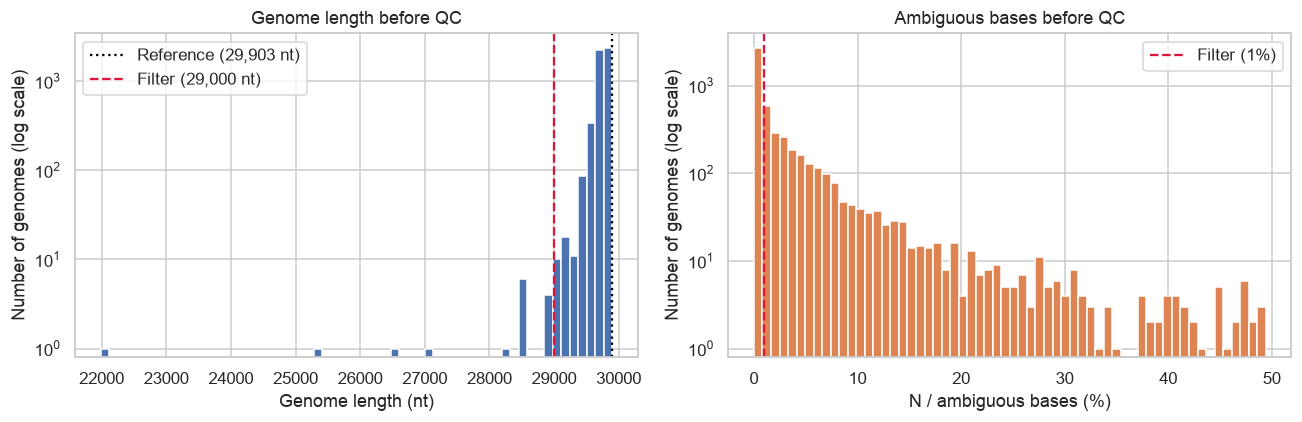

Median length: 29,764 nt | shortest: 21,984 | longest: 29,903
99.7% of genomes are >= 29,000 nt; 55.2% have <= 1% ambiguous bases.


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(uniq["length"], bins=60, color="#4C72B0")
ax[0].axvline(REF_LEN, color="black", ls=":", label=f"Reference ({REF_LEN:,} nt)")
ax[0].axvline(MIN_LEN, color="crimson", ls="--", label=f"Filter ({MIN_LEN:,} nt)")
ax[0].set(yscale="log", xlabel="Genome length (nt)", ylabel="Number of genomes (log scale)",
          title="Genome length before QC", ylim=(0.8, None))
ax[0].legend()

ax[1].hist(uniq["ambig_frac"] * 100, bins=60, color="#DD8452")
ax[1].axvline(MAX_AMBIG_FRAC * 100, color="crimson", ls="--", label=f"Filter ({MAX_AMBIG_FRAC:.0%})")
ax[1].set(yscale="log", xlabel="N / ambiguous bases (%)", ylabel="Number of genomes (log scale)",
          title="Ambiguous bases before QC", ylim=(0.8, None))
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_length_and_ambiguity.png", bbox_inches="tight"); plt.show()

print(f"Median length: {uniq['length'].median():,.0f} nt | shortest: {uniq['length'].min():,} | longest: {uniq['length'].max():,}")
print(f"{(uniq['length'] >= MIN_LEN).mean():.1%} of genomes are >= {MIN_LEN:,} nt; "
      f"{(uniq['ambig_frac'] <= MAX_AMBIG_FRAC).mean():.1%} have <= {MAX_AMBIG_FRAC:.0%} ambiguous bases.")

**Interpretation, Figure 1 (edit after running):**
- *What I see:* most genomes are close to the 29,903 nt reference (median 29,764 nt; shortest 21,984). The ambiguity plot has a long tail: only 55.2% of genomes have ≤ 1% N bases, and some have up to about 50%.
- *Biology check:* SARS-CoV-2 genomes are about 29.9 kb, so this matches expectation; the median is slightly shorter because the ends are often not sequenced.
- *Why it matters:* the length filter (red line) barely matters, while the ambiguity filter removes the largest share. Genomes with many N bases would produce incomplete genes and distort the PCA.

### Figure 2 — Genomes per WHO clade / variant

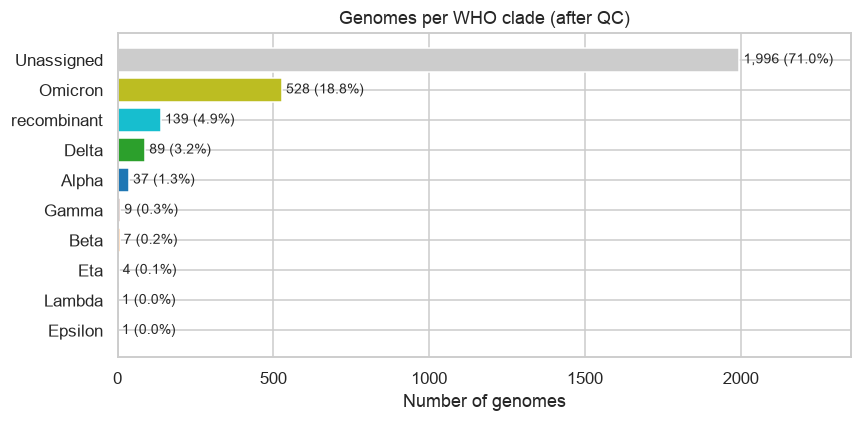

Most common: Unassigned (1,996); rarest: Epsilon (1). Countries represented: 90; top 3: {'USA': 1455, 'United Kingdom': 416, 'China': 272}


In [18]:
counts = eda["clade"].value_counts()
fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(counts))))
order = list(counts.index[::-1])                       # largest bar at the top
ax.barh(order, [counts[c] for c in order], color=[CLADE_COLORS[c] for c in order])
for i, c in enumerate(order):
    ax.text(counts[c], i, f" {counts[c]:,} ({counts[c] / len(eda):.1%})", va="center", fontsize=9)
ax.set(xlabel="Number of genomes", ylabel="", title="Genomes per WHO clade (after QC)")
ax.set_xlim(0, counts.max() * 1.18)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_clade_counts.png", bbox_inches="tight"); plt.show()

print(f"Most common: {counts.index[0]} ({counts.iloc[0]:,}); rarest: {counts.index[-1]} ({counts.iloc[-1]:,}). "
      f"Countries represented: {eda['country'].nunique()}; top 3: {eda['country'].value_counts().head(3).to_dict()}")

**Interpretation, Figure 2 (edit after running):**
- *What I see:* the dataset is dominated by Unassigned (1,996; 71.0%), then Omicron (528; 18.8%), recombinant (139; 4.9%), Delta (89) and Alpha (37). Gamma, Beta, Eta, Lambda and Epsilon each have 9 or fewer genomes. Ninety countries are represented, but USA (1,455), UK (416) and China (272) supply about 76% of genomes.
- *Why it matters:* the data is unbalanced in clade and geography, so Stage 5 comparisons are reliable for Omicron but not for the rarest clades, which can look different by chance.
- *Caveat:* Unassigned means no WHO label. 

### Figure 3 — Genomes over time by clade

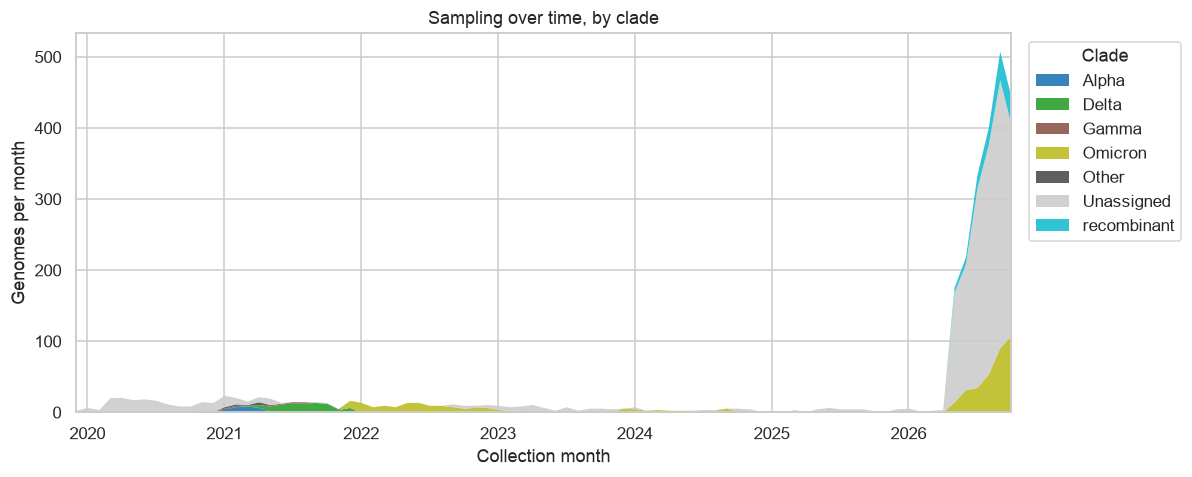

Date range: 2019-12-26 to 2026-10-25; busiest month: 2026-09 (508 genomes)


In [19]:
d = eda.dropna(subset=["date_parsed"])
ts = (d.groupby([d["date_parsed"].dt.to_period("M").dt.to_timestamp(), "clade_plot"])
        .size().unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(11, 4.5))
ts.plot.area(ax=ax, linewidth=0, alpha=0.9, color=[CLADE_COLORS[c] for c in ts.columns])
ax.set(xlabel="Collection month", ylabel="Genomes per month", title="Sampling over time, by clade")
ax.legend(title="Clade", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_clades_over_time.png", bbox_inches="tight"); plt.show()

print(f"Date range: {d['date_parsed'].min():%Y-%m-%d} to {d['date_parsed'].max():%Y-%m-%d}; "
      f"busiest month: {ts.sum(axis=1).idxmax():%Y-%m} ({ts.sum(axis=1).max():,} genomes)")

**Interpretation, Figure 3 (edit after running):**
- *What I see:* collection dates run from Dec 2019 to Oct 2026. For most of 2020–2026 there are only a few to about 20 genomes per month, followed by a sharp spike in 2026 peaking in Sept 2026 (508 genomes), mostly Unassigned. Alpha and Delta appear as thin bands around 2021, with Omicron after them. [Check this against your plot.]
- *Biology check:* Alpha and Delta being replaced by Omicron matches the known succession of variant waves.
- *Caveat:* sampling is heavily weighted toward the last few months, so peaks reflect sequencing effort rather than infection levels, and time-based results must account for this.

### Figure 4 — PCA of genetic variation
For a random sample of genomes, each position that differs from the reference in 1–99% of genomes becomes a 0/1 feature (1 = differs from the reference; missing calls are set to the site's average). PCA then shows whether genomes cluster by clade.

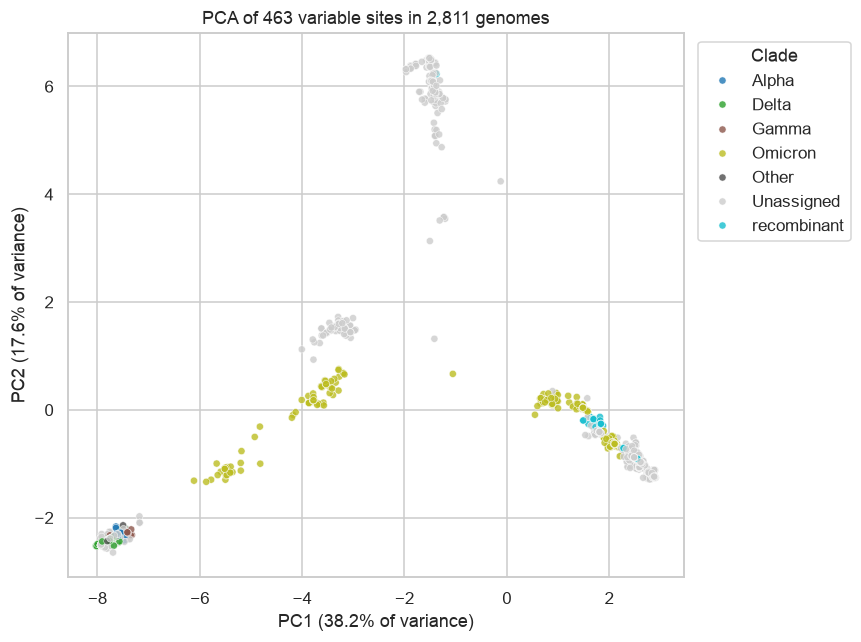

PC1+PC2 explain 55.7% of the variance.
Genomes furthest from the centre (possible outliers): ['IND/Barcode41MN908947.3/2021', 'EGY/CCHE57357_W4_A030/2021', 'EGY/CCHE57357_W4_A060/2021', 'IND/Barcode43MN908947.3/2021', 'EGY/CCHE57357_Wave_4_078/2021']


In [20]:
diff, miss = np.vstack(snp_diff), np.vstack(snp_miss)
n_nonmiss = (~miss).sum(axis=0)
freq = np.divide(diff.sum(axis=0), n_nonmiss, out=np.zeros(REF_LEN), where=n_nonmiss > 0)
sites = np.where((freq >= 0.01) & (freq <= 0.99) & (n_nonmiss >= 0.9 * len(diff)))[0]
if len(sites) < 2:
    raise ValueError("Fewer than 2 variable sites; relax the 1-99% frequency window")

X = diff[:, sites].astype(np.float32)
m = miss[:, sites]
X[m] = np.take(freq[sites], np.where(m)[1])          # fill missing calls with the site mean

pca = PCA(n_components=min(10, X.shape[0], X.shape[1]), random_state=42)
pcs = pca.fit_transform(X)
labels = eda.set_index("strain")["clade_plot"].reindex(snp_ids).values

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=labels, hue_order=sorted(set(labels)), s=22, alpha=0.8,
                palette=CLADE_COLORS, ax=ax)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)",
       ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)",
       title=f"PCA of {len(sites):,} variable sites in {len(snp_ids):,} genomes")
ax.legend(title="Clade", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_pca_by_clade.png", bbox_inches="tight"); plt.show()

dist = np.hypot(pcs[:, 0] - pcs[:, 0].mean(), pcs[:, 1] - pcs[:, 1].mean())
far = np.argsort(dist)[::-1][:5]
print("PC1+PC2 explain", f"{pca.explained_variance_ratio_[:2].sum():.1%}", "of the variance.")
print("Genomes furthest from the centre (possible outliers):", [snp_ids[i] for i in far])

**Interpretation, Figure 4 (edit after running):**
- *What I see:* PCA of 463 variable sites in 2,811 genomes; PC1 and PC2 explain 55.7% of the variance. There are several distinct groups: a tight group at far left (Alpha, Delta, Gamma and some unlabelled genomes), a chain of mostly Omicron genomes in the middle, a group at right mixing Omicron, recombinant and Unassigned, and a separate group at the top made up only of Unassigned genomes. The chain shape fits gradual accumulation of mutations.
- *Outliers:* the genomes furthest from the centre are [from check (b): which clade/lineage, and which cluster they sit in]. "Furthest from the centre" picks the edge of the most distant cluster, so they may be real members of it rather than errors. Their IDs contain MN908947.3, the accession of the original Wuhan genome, so check them in Stage 5.
- *Biology check:* Alpha, Delta and Gamma overlap because the large Omicron-versus-rest difference dominates PC1 and PC2; they may separate on later components.

### Figure 5 — Gene extraction: completeness and length vs. reference

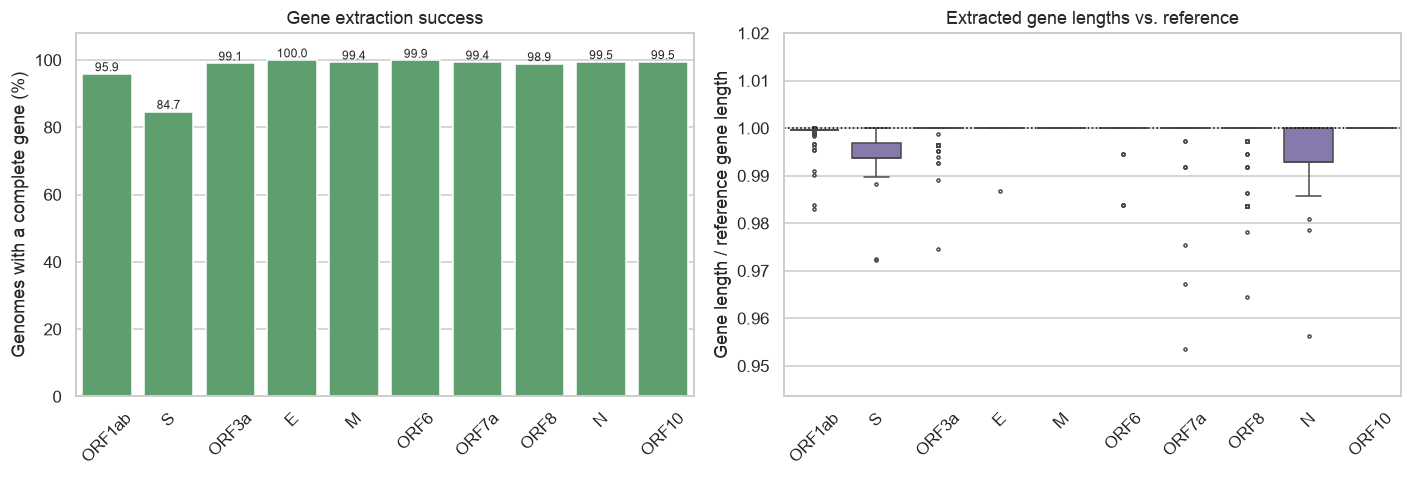

gene          ORF1ab     S  ORF3a      E      M  ORF6  ORF7a  ORF8     N  ORF10
pct_complete    95.9  84.7   99.1  100.0   99.4  99.9   99.4  98.9  99.5   99.5
pct_in_frame     NaN  99.7   99.8  100.0  100.0  99.9   99.9  97.8  99.9  100.0


In [21]:
rel = pd.DataFrame({g: gene_df.loc[gene_df[f"{g}_ok"], f"{g}_len"] / (GENES0[g][1] - GENES0[g][0])
                    for g in GENES0})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=gene_summary.index, y=gene_summary["pct_complete"], color="#55A868", ax=ax[0])
for i, v in enumerate(gene_summary["pct_complete"]):
    ax[0].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax[0].set(ylabel="Genomes with a complete gene (%)", xlabel="", title="Gene extraction success", ylim=(0, 108))
ax[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=rel, color="#8172B3", fliersize=2, ax=ax[1])
ax[1].axhline(1, color="black", ls=":", lw=1)
ax[1].set(ylabel="Gene length / reference gene length", xlabel="", title="Extracted gene lengths vs. reference",
          ylim=(min(0.95, rel.min().min() - 0.01), 1.02))
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_gene_extraction.png", bbox_inches="tight"); plt.show()

print(gene_summary[["pct_complete", "pct_in_frame"]].round(1).T.to_string())

In [22]:
# (a) Why are S and ORF1ab incomplete?
for g in ["S", "ORF1ab"]:
    low_cov = int((gene_df[f"{g}_cov"] < MIN_GENE_COV).sum())
    too_n = int(((gene_df[f"{g}_cov"] >= MIN_GENE_COV) & ~gene_df[f"{g}_ok"]).sum())
    print(f"{g}: incomplete={low_cov + too_n} (part of gene missing: {low_cov}, aligned but >1% N: {too_n})")

# (b) What are the PCA 'outliers'?
out_ids = [snp_ids[i] for i in far]
print(eda.set_index("strain").loc[out_ids, ["clade", "pango_lineage", "date", "country"]]
      .assign(PC1=pcs[far, 0].round(1), PC2=pcs[far, 1].round(1)))

# (c) What is inside 'Unassigned'?
un = eda[eda["clade"] == "Unassigned"]
print(un["pango_lineage"].value_counts().head(8))
print(un["date_parsed"].dt.year.value_counts().sort_index())

S: incomplete=431 (part of gene missing: 24, aligned but >1% N: 407)
ORF1ab: incomplete=116 (part of gene missing: 0, aligned but >1% N: 116)
                               clade pango_lineage        date country  PC1  \
strain                                                                        
IND/Barcode41MN908947.3/2021   Delta     B.1.617.2  2021-09-10   India -8.0   
EGY/CCHE57357_W4_A030/2021     Delta     B.1.617.2  2021-09-02   Egypt -8.0   
EGY/CCHE57357_W4_A060/2021     Delta        AY.122  2021-08-30   Egypt -8.0   
IND/Barcode43MN908947.3/2021   Delta     B.1.617.2  2021-09-10   India -8.0   
EGY/CCHE57357_Wave_4_078/2021  Delta     B.1.617.2  2021-10-23   Egypt -8.0   

                               PC2  
strain                              
IND/Barcode41MN908947.3/2021  -2.5  
EGY/CCHE57357_W4_A030/2021    -2.5  
EGY/CCHE57357_W4_A060/2021    -2.5  
IND/Barcode43MN908947.3/2021  -2.5  
EGY/CCHE57357_Wave_4_078/2021 -2.5  
pango_lineage
XFG.23.1.3    290
XFG.6.3.3    

**Interpretation, Figure 5 (edit after running):**
- *What I see:* the share of complete genes is ≥ 98.9% for 8 of 10 genes (E: 100%) and lowest for S (84.7%) and ORF1ab (95.9%). 
- *Biology check:* extracted lengths are close to 1.0 × the reference. S and N are slightly shorter, which is consistent with known Omicron deletions (for example a 9-nt deletion in N), and ORF8 has the most outliers.
- *Why it matters:* genes with the most complete copies (E, ORF6, N, ORF10) give the largest sample. A spike analysis would use about 2,380 of 2,811 genomes.

---
## Summary
- **Stage 3:** … raw sequences → … clean genomes (see `results/qc_funnel.csv`); genes extracted with minimap2 + reference coordinates, coordinates validated against the reference ORFs.
- **Stage 4:** five figures in `results/figures/`; main findings: …
- **Hand-off:** `data/processed/` holds the cleaned genomes, one FASTA per gene and the matching metadata for the core analysis.